# Dự đoán bệnh tiểu đường bằng SVM
## 1. Import lib

In [ ]:

from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay)
RANDOM_STATE = 42

## 2. Đọc dữ liệu

In [ ]:
DATA_PATH = Path("../data/diabetes_prediction_dataset.csv")  
if not DATA_PATH.exists():
    candidates = sorted(Path('/kaggle/input').rglob('train.csv')) if Path('/kaggle/input').exists() else []
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError('Hãy đặt diabetes_prediction_dataset.csv cạnh notebook hoặc sửa DATA_PATH tới file  diabetes_prediction_dataset.csv.')
DATA_PATH = Path(DATA_PATH)
df = pd.read_csv(DATA_PATH)
print('Đã đọc:', DATA_PATH.resolve())
print('Kích thước ban đầu:', df.shape)
display(df.head())

Đã đọc: C:\Users\thanh\Desktop\Machine Learning\kaggle\Diabetes-EDA\data\diabetes_prediction_dataset.csv
Kích thước ban đầu: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 3. Kiểm tra và làm sạch
Thuộc tính số: tuổi, tăng huyết áp, bệnh tim, BMI, HbA1c, đường huyết. Thuộc tính phân loại: giới tính và lịch sử hút thuốc.

Trong bài thực hành này, coi các dòng trùng hoàn toàn là bản ghi lặp và loại trước khi chia, để bản sao giống nhau không nằm ở cả train và test. Dữ liệu không có mã bệnh nhân nên không thể xác minh những dòng trùng có thực sự thuộc cùng người; báo cáo cần nêu giả định này. Giữ chuỗi No Info như một nhóm của lịch sử hút thuốc, không tự suy ra là không hút. Không tự thay số 0 thành thiếu: 0 là giá trị hợp lệ ở các cột nhị phân.

Số dòng trùng hoàn toàn: 3854
Kích thước sau bỏ trùng: (96146, 9)


,Số giá trị thiếu
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender,0
smoking_history,0
diabetes,0


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000
mean,41.794326,0.077601,0.040803,27.321461,5.532609,138.218231
std,22.462948,0.267544,0.197833,6.767716,1.073232,40.909771
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.400000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.860000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000


,Số mẫu,Tỉ lệ
diabetes,,
0,87664,0.91178
1,8482,0.08822


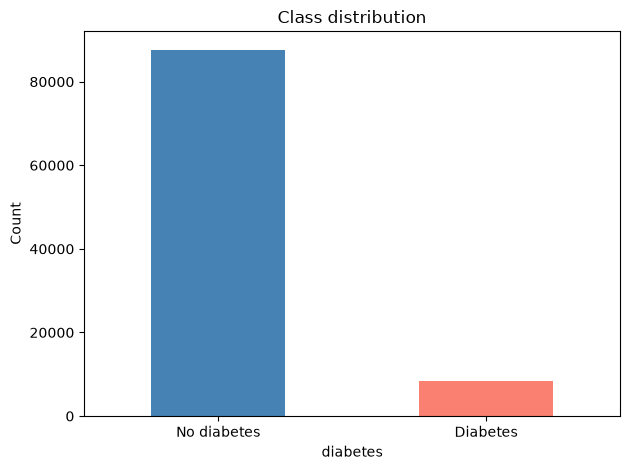

In [ ]:
numeric_features = ['age', 'hypertension', 'heart_disease', 'bmi',
                    'HbA1c_level', 'blood_glucose_level']
categorical_features = ['gender', 'smoking_history']
features = numeric_features + categorical_features
target = 'diabetes'
required = features + [target]
missing_columns = set(required) - set(df.columns)
if missing_columns:
    raise ValueError(f'Thiếu cột {missing_columns}. Cần Diabetes prediction dataset, không phải Pima/Titanic.')
print('Số dòng trùng hoàn toàn:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
if df[target].isna().any() or set(df[target].unique()) != {0, 1}:
    raise ValueError('Nhãn diabetes phải có hai lớp 0/1 và không được thiếu.')
print('Kích thước sau bỏ trùng:', df.shape)
display(df[required].isna().sum().to_frame('Số giá trị thiếu'))
display(df[numeric_features].describe())
display(pd.DataFrame({'Số mẫu': df[target].value_counts().sort_index(),
                      'Tỉ lệ': df[target].value_counts(normalize=True).sort_index()}))
df[target].value_counts().sort_index().plot.bar(rot=0, color=['steelblue', 'salmon'])
plt.xticks([0, 1], ['No diabetes', 'Diabetes'])
plt.ylabel('Count')
plt.title('Class distribution')
plt.tight_layout()
plt.show()

## 4. Chia train/test 80/20 và tạo Pipeline
`stratify=y` giữ gần đúng tỉ lệ lớp giữa hai tập. Điền thiếu cột số bằng trung vị, cột phân loại bằng mode; chuẩn hóa các cột số bằng StandardScaler; mã hóa nhóm bằng one-hot.

SVM nhạy với thang đo nên bước chuẩn hóa cần thiết. Tất cả bước học từ dữ liệu nằm trong Pipeline để được fit riêng trong mỗi fold huấn luyện, tránh rò rỉ dữ liệu. Không dùng SMOTE trước khi chia tập.

In [ ]:
X = df[features].copy()
y = df[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])
svm_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('svm', LinearSVC(dual=False, max_iter=20000, random_state=RANDOM_STATE))
])

Train: (76916, 8) | Test: (19230, 8)


## 5. Chọn tham số bằng GridSearchCV
Thử C = 0.1, 1, 10 và hai lựa chọn trọng số lớp. Cross-validation 3 fold chỉ dùng tập train. Chọn cấu hình có F1 cao nhất để cân bằng precision và recall của lớp mắc bệnh.

F1 ở bước lựa chọn là trung bình qua các fold; điểm CV của cấu hình tốt nhất là điểm dùng để chọn tham số, không phải đánh giá độc lập cuối cùng. Tập test được giữ riêng cho bước sau.

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    'svm__C': [0.1, 1.0, 10.0],
    'svm__class_weight': [None, 'balanced']
}
search = GridSearchCV(
    svm_pipeline, param_grid, scoring={'f1': 'f1', 'recall': 'recall', 'roc_auc': 'roc_auc'},
    refit='f1', cv=cv, n_jobs=1, return_train_score=False, error_score='raise')
start = perf_counter()
search.fit(X_train, y_train)
training_seconds = perf_counter() - start
best_model = search.best_estimator_
print('Tham số tốt nhất:', search.best_params_)
print('CV F1 tốt nhất:', round(search.best_score_, 4))
print('Thời gian tìm tham số và refit (giây):', round(training_seconds, 2))
cv_table = pd.DataFrame(search.cv_results_)[[
    'param_svm__C', 'param_svm__class_weight', 'mean_test_f1',
    'std_test_f1', 'mean_test_recall', 'mean_test_roc_auc']]
display(cv_table.sort_values('mean_test_f1', ascending=False))

Tham số tốt nhất: {'svm__C': 1.0, 'svm__class_weight': None}
CV F1 tốt nhất: 0.7248
Thời gian tìm tham số và refit (giây): 3.54


,param_svm__C,param_svm__class_weight,mean_test_f1,std_test_f1,mean_test_recall,mean_test_roc_auc
4,10.0,NaN,0.724839,0.008356,0.608606,0.961328
2,1.0,NaN,0.724839,0.008356,0.608606,0.961327
0,0.1,NaN,0.724677,0.008370,0.608311,0.961326
5,10.0,balanced,0.579948,0.003869,0.882700,0.962244
3,1.0,balanced,0.579921,0.003906,0.882700,0.962243
1,0.1,balanced,0.579824,0.003969,0.882552,0.962240


## 5B. So sánh bốn kernel theo bài mẫu SVM
Thử SVC với linear, poly, rbf, sigmoid; C = 1, gamma = scale, degree = 3 mặc định cho poly. Dùng accuracy validation để chọn kernel như ý tưởng của mẫu, nhưng thay vì chọn bằng test, dùng CV phân tầng 3 fold chỉ trên train.

Dữ liệu có khoảng 96 nghìn dòng sau bỏ trùng, kernel SVC có thể chạy rất lâu. Mặc định lấy 6.000 mẫu phân tầng từ train để khảo sát, dùng cùng mẫu và fold cho cả bốn kernel. Tập test 20% vẫn giữ nguyên. Đổi KERNEL_SAMPLE_SIZE = None nếu muốn huấn luyện và khảo sát trên toàn bộ train; thời gian sẽ tăng đáng kể.

Phần 5 dùng LinearSVC trên toàn bộ train và chọn theo F1. Phần 5B là thí nghiệm bổ sung dùng SVC trên mẫu train và chọn kernel theo accuracy. Các khác biệt này được ghi rõ để không quy mọi khác biệt kết quả về kernel.

In [ ]:
from sklearn.base import clone
from sklearn.svm import SVC
KERNEL_SAMPLE_SIZE = 6000
if KERNEL_SAMPLE_SIZE is not None and len(X_train) > KERNEL_SAMPLE_SIZE:
    X_kernel, _, y_kernel, _ = train_test_split(
        X_train, y_train, train_size=KERNEL_SAMPLE_SIZE,
        stratify=y_train, random_state=RANDOM_STATE)
else:
    X_kernel, y_kernel = X_train, y_train
print('Số mẫu khảo sát kernel:', len(X_kernel), '/', len(X_train), 'mẫu train')
kernel_pipeline = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('svm', SVC(C=1.0, gamma='scale', cache_size=512))
])
kernel_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
kernel_search = GridSearchCV(
    kernel_pipeline, {'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
    scoring={'accuracy': 'accuracy', 'f1': 'f1', 'recall': 'recall', 'roc_auc': 'roc_auc'},
    refit='accuracy', cv=kernel_cv, return_train_score=True, n_jobs=1,
    error_score='raise')
start = perf_counter()
kernel_search.fit(X_kernel, y_kernel)
print('Thời gian khảo sát kernel và refit:', round(perf_counter()-start, 2), 'giây')
best_kernel_model = kernel_search.best_estimator_
print('Kernel tốt nhất theo CV accuracy:', kernel_search.best_params_['svm__kernel'])
print('CV accuracy tốt nhất:', round(kernel_search.best_score_, 4))
kernel_results = pd.DataFrame(kernel_search.cv_results_)
display(kernel_results[['param_svm__kernel', 'mean_train_accuracy', 'mean_test_accuracy',
    'std_test_accuracy', 'mean_test_f1', 'mean_test_recall', 'mean_test_roc_auc', 'mean_fit_time']])

Số mẫu khảo sát kernel: 6000 / 76916 mẫu train
Thời gian khảo sát kernel và refit: 3.72 giây
Kernel tốt nhất theo CV accuracy: poly
CV accuracy tốt nhất: 0.9612


,param_svm__kernel,mean_train_accuracy,mean_test_accuracy,std_test_accuracy,mean_test_f1,mean_test_recall,mean_test_roc_auc,mean_fit_time
0,linear,0.960917,0.960000,0.003937,0.727587,0.606874,0.962058,0.079028
1,poly,0.968750,0.961167,0.004922,0.737156,0.618205,0.917227,0.079224
2,rbf,0.965000,0.959833,0.004696,0.718915,0.582263,0.887229,0.096141
3,sigmoid,0.912583,0.915500,0.011576,0.496089,0.476278,0.884207,0.083745


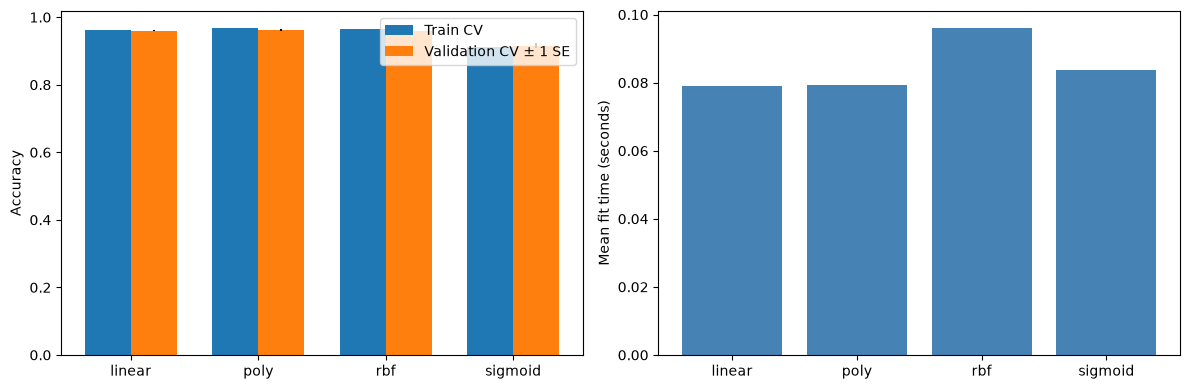

In [ ]:
x = np.arange(len(kernel_results))
width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x-width/2, kernel_results['mean_train_accuracy'], width, label='Train CV')
axes[0].bar(x+width/2, kernel_results['mean_test_accuracy'], width,
    yerr=kernel_results['std_test_accuracy']/np.sqrt(kernel_cv.get_n_splits()), label='Validation CV ± 1 SE')
axes[0].set_xticks(x, kernel_results['param_svm__kernel'].astype(str))
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[1].bar(x, kernel_results['mean_fit_time'], color='steelblue')
axes[1].set_xticks(x, kernel_results['param_svm__kernel'].astype(str))
axes[1].set_ylabel('Mean fit time (seconds)')
plt.tight_layout()
plt.show()

## 6. Đánh giá trên test
Accuracy có thể cao chỉ nhờ đoán lớp phổ biến. Vì vậy, so sánh thêm balanced accuracy, precision, recall, F1, ROC-AUC và Average Precision. AP hữu ích để đánh giá xếp hạng lớp dương khi hai lớp lệch nhau.

LinearSVC không xuất xác suất. Dùng decision_function để tính ROC-AUC/AP và vẽ đường cong; đây là điểm quyết định, không phải xác suất mắc bệnh. Ngưỡng mặc định là 0.

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,,
Baseline,0.9118,0.5000,0.0000,0.0000,0.0000,0.5000,0.0882
Linear SVM,0.9597,0.8045,0.8939,0.6162,0.7295,0.9595,0.8166
SVC best kernel (train sample),0.9612,0.8048,0.9173,0.6150,0.7363,0.9231,0.7971


LinearSVC fit toàn bộ train; SVC fit trên 6000 mẫu train.
Train F1: 0.7241
Thời gian dự đoán test (giây): 0.03
              precision    recall  f1-score   support

 No diabetes       0.96      0.99      0.98     17534
    Diabetes       0.89      0.62      0.73      1696

    accuracy                           0.96     19230
   macro avg       0.93      0.80      0.85     19230
weighted avg       0.96      0.96      0.96     19230



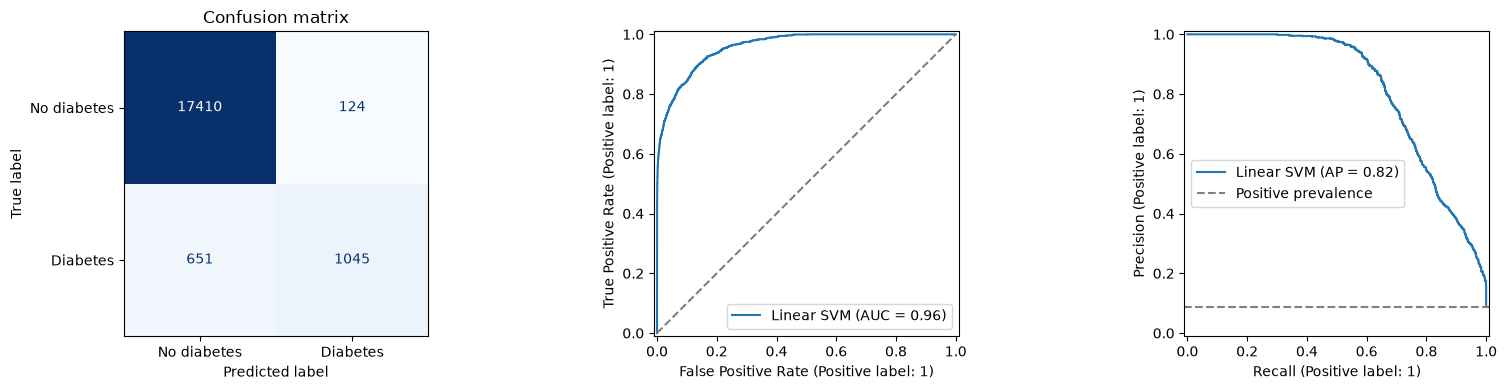

In [ ]:
start = perf_counter()
y_pred = best_model.predict(X_test)
y_score = best_model.decision_function(X_test)
prediction_seconds = perf_counter() - start
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

def metrics_row(name, actual, predicted, scores):
    return {'Model': name,
        'Accuracy': accuracy_score(actual, predicted),
        'Balanced accuracy': balanced_accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted, zero_division=0),
        'Recall': recall_score(actual, predicted, zero_division=0),
        'F1': f1_score(actual, predicted, zero_division=0),
        'ROC-AUC': roc_auc_score(actual, scores),
        'Average Precision': average_precision_score(actual, scores)}
results = pd.DataFrame([
    metrics_row('Baseline', y_test, baseline.predict(X_test), baseline.predict_proba(X_test)[:, 1]),
    metrics_row('Linear SVM', y_test, y_pred, y_score),
    metrics_row('SVC best kernel (train sample)', y_test,
                best_kernel_model.predict(X_test), best_kernel_model.decision_function(X_test))
]).set_index('Model')
display(results.round(4))
print('LinearSVC fit toàn bộ train; SVC fit trên', len(X_kernel), 'mẫu train.')
print('Train F1:', round(f1_score(y_train, best_model.predict(X_train)), 4))
print('Thời gian dự đoán test (giây):', round(prediction_seconds, 4))
print(classification_report(y_test, y_pred, labels=[0, 1],
      target_names=['No diabetes', 'Diabetes'], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1],
    display_labels=['No diabetes', 'Diabetes'], cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Confusion matrix')
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1], name='Linear SVM')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[2], name='Linear SVM')
axes[2].axhline(y_test.mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[2].legend()
plt.tight_layout()
plt.show()

Selected SVC kernel: poly
              precision    recall  f1-score   support

 No diabetes       0.96      0.99      0.98     17534
    Diabetes       0.92      0.61      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.94      0.80      0.86     19230
weighted avg       0.96      0.96      0.96     19230



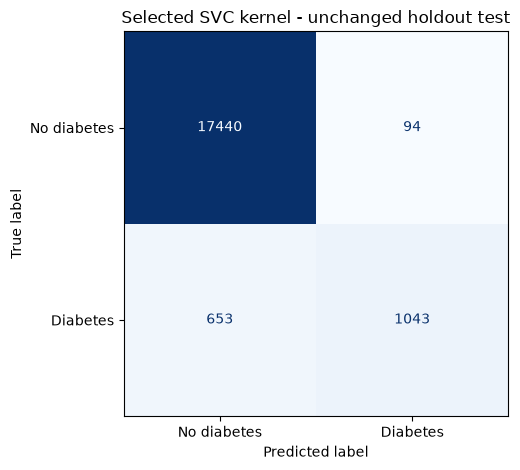

In [ ]:
# Ma trận nhầm lẫn và classification report của SVC có kernel chọn theo CV.
kernel_pred = best_kernel_model.predict(X_test)
print('Selected SVC kernel:', kernel_search.best_params_['svm__kernel'])
print(classification_report(y_test, kernel_pred, labels=[0, 1],
      target_names=['No diabetes', 'Diabetes'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, kernel_pred, labels=[0, 1],
    display_labels=['No diabetes', 'Diabetes'], cmap='Blues', colorbar=False)
plt.title('Selected SVC kernel - unchanged holdout test')
plt.tight_layout()
plt.show()

## 7. Xem hệ số và dự đoán mẫu mới
Hệ số dương đẩy điểm quyết định về lớp 1, hệ số âm về lớp 0, khi giữ các thuộc tính còn lại cố định. Độ lớn hệ số phụ thuộc cách mã hóa và chuẩn hóa; không diễn giải thành quan hệ nhân quả hay kết luận lâm sàng.

,Coefficient
num__HbA1c_level,0.691910
cat__gender_Other,-0.395010
num__blood_glucose_level,0.394983
cat__gender_Female,-0.345218
cat__smoking_history_No Info,-0.278549
cat__gender_Male,-0.264360
num__age,0.261286
cat__smoking_history_not current,-0.161045
num__bmi,0.155446
cat__smoking_history_never,-0.148340


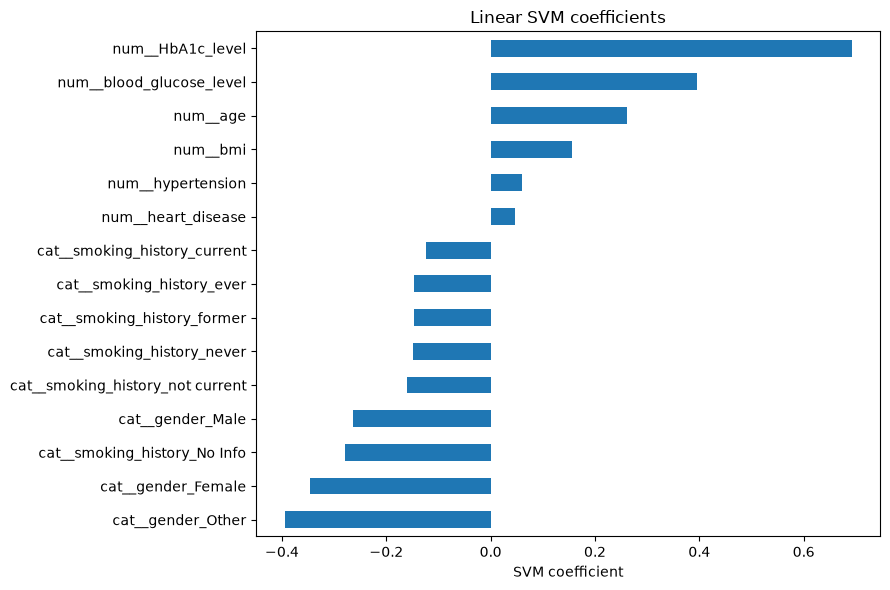

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender,smoking_history,Predicted_diabetes,Decision_score
0,45,0,0,25.0,5.2,100,Female,never,0,-2.122145
1,65,1,0,32.0,8.0,220,Male,former,1,1.542354


In [ ]:
feature_names = best_model.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.Series(best_model.named_steps['svm'].coef_[0], index=feature_names)
display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).to_frame('Coefficient'))
coefficients.sort_values().plot.barh(figsize=(9, 6))
plt.xlabel('SVM coefficient')
plt.title('Linear SVM coefficients')
plt.tight_layout()
plt.show()
new_samples = pd.DataFrame([
    {'gender': 'Female', 'age': 45, 'hypertension': 0, 'heart_disease': 0,
     'smoking_history': 'never', 'bmi': 25.0, 'HbA1c_level': 5.2, 'blood_glucose_level': 100},
    {'gender': 'Male', 'age': 65, 'hypertension': 1, 'heart_disease': 0,
     'smoking_history': 'former', 'bmi': 32.0, 'HbA1c_level': 8.0, 'blood_glucose_level': 220}
])[features]
new_results = new_samples.copy()
new_results['Predicted_diabetes'] = best_model.predict(new_samples)
new_results['Decision_score'] = best_model.decision_function(new_samples)
display(new_results)